# UMI-XDOF Motion Analysis with DHB-XR

This notebook demonstrates the **complete DHB-XR pipeline** on real UMI-XDOF teleoperation data (pick-place tasks). We cover:
- **Trajectory preprocessing** and quality diagnostics
- **DHB encoding/decoding** with robustness features
- **Motion retrieval** using invariant similarity
- **VLA tokenization** for action discretization
- **Generative modeling** with Variational Flow Matching

**Run inside dhb_xr with pixi:**
```bash
cd dhb_xr
pixi run download-xdof   # optional: fetch samples from S3 (requires AWS CLI)
pixi run notebook        # start Jupyter; open this notebook
```

**Sections:**
1. **Setup and data loading** — Load numpy trajectories
2. **DHB Encoding** — Encode trajectories to SE(3)-invariant representations
   - 2a. **Quality diagnostics** — Detect reversals, zero-motion, alignment issues
   - 2b. **Time-invariant encoding (DHB-TI)** — Speed-independent representations
3. **Motion Database** — Retrieve similar motions by invariant similarity
   - 3b. **Trajectory adaptation** — Retarget to new start/goal (Fatrop/CasADi)
   - 3c. **GPU batch decode** — CusADi for fast parallel decoding
4. **VLA Tokenization** — Residual VQ for discrete action tokens
5. **Token Compression** — BPE, entropy coding, RLE analysis
6. **Visualization & Summary** — PCA embeddings, retrieval accuracy
7. **Variational Flow Matching** — Multi-modal trajectory generation

## 1. Setup and Data Loading

Load UMI-XDOF episodes from the local data directory (populated by `scripts/download_xdof_samples.py`). We use numpy files only—no xdof_sdk dependency.

In [1]:
import numpy as np
from pathlib import Path

from dhb_xr.utils import list_xdof_episodes, load_xdof_episode

# Data root: same as download script default
DATA_ROOT = Path("/home/andypark/Projects/data/xdof-umi/xdof_samples")
episodes = list_xdof_episodes(DATA_ROOT)
print(f"Found {len(episodes)} episodes across tasks")
tasks = sorted(set(t for t, _ in episodes))
print(f"Tasks: {tasks}")

Found 55 episodes across tasks
Tasks: ['pick_place_beverage', 'pick_place_candy_bag', 'pick_place_chips_bag', 'pick_place_cleaning_sponge', 'pick_place_dish_detergent', 'pick_place_paper_towel', 'pick_place_shaving_razor', 'pick_place_soup_can', 'pick_place_toothpaste', 'pick_place_yoghurt', 'sorting_stationery', 'untangle_cables']


In [2]:
# Load trajectories (left arm) for all episodes
ARM = "left"
trajectories = []  # list of (positions, quaternions)
meta = []          # (task, episode_path)

for task_name, ep_path in episodes:
    out = load_xdof_episode(ep_path, arm=ARM)
    if out is None:
        continue
    pos, quat = out
    if len(pos) < 10:  # skip very short trajectories
        continue
    trajectories.append((pos, quat))
    meta.append({"task": task_name, "episode": ep_path.name})

print(f"Loaded {len(trajectories)} trajectories")
# Show one example shape
if trajectories:
    p, q = trajectories[0]
    print(f"Example: positions {p.shape}, quaternions {q.shape}")

Loaded 55 trajectories
Example: positions (240, 3), quaternions (240, 4)


## 2. DHB Encoding of Real Trajectories

**DHB (Discrete Helical Basis)** encodes SE(3) trajectories as sequences of geometric invariants:
- **Linear invariants** (4 values): displacement magnitude + 3 Euler angles for frame rotation
- **Angular invariants** (4 values): rotation magnitude + 3 Euler angles

These invariants are **SE(3)-invariant**: the same motion executed at different positions/orientations produces identical invariants. This enables motion comparison, retrieval, and generalization across different robot configurations.

**Key insight**: Real teleoperation data often has quality issues (reversals, zero-motion segments) that can cause encoding problems. We first analyze and preprocess the data before encoding.

## 2a. Trajectory Quality Diagnostics

Before encoding, analyze trajectory quality to detect potential issues:
- **180° direction reversals**: Can cause Euler singularities in frame transport
- **Zero-motion segments**: Undefined tangent frames when the robot is stationary
- **Initial direction misalignment**: Reconstruction error with default frames

This section uses the new `analyze_trajectory()` function to assess each trajectory.

In [3]:
from dhb_xr.preprocessing import (
    TrajectoryPreprocessor,
    analyze_trajectory,
    TrajectoryDiagnostics,
)

# Analyze all trajectories
diagnostics_results = []
for i, (pos, quat) in enumerate(trajectories):
    diag = analyze_trajectory(pos, quat)
    diagnostics_results.append({
        'idx': i,
        'task': meta[i]['task'],
        'num_samples': diag.num_samples,
        'trajectory_length': diag.trajectory_length,
        'num_reversals': diag.num_reversals,
        'num_zero_motion': diag.num_zero_motion_segments,
        'alignment_angle_deg': np.degrees(diag.alignment_angle_to_x),
        'is_well_conditioned': diag.is_well_conditioned,
    })

# Summary statistics
total = len(diagnostics_results)
well_conditioned = sum(1 for d in diagnostics_results if d['is_well_conditioned'])
with_reversals = sum(1 for d in diagnostics_results if d['num_reversals'] > 0)
with_zero_motion = sum(1 for d in diagnostics_results if d['num_zero_motion'] > 0)
needs_alignment = sum(1 for d in diagnostics_results if d['alignment_angle_deg'] > 30)

print(f"Trajectory Quality Summary ({total} trajectories)")
print(f"  Well-conditioned: {well_conditioned}/{total} ({100*well_conditioned/total:.1f}%)")
print(f"  With reversals: {with_reversals}/{total}")
print(f"  With zero-motion: {with_zero_motion}/{total}")
print(f"  Needs alignment (>30°): {needs_alignment}/{total}")

Trajectory Quality Summary (55 trajectories)
  Well-conditioned: 0/55 (0.0%)
  With reversals: 55/55
  With zero-motion: 52/55
  Needs alignment (>30°): 47/55


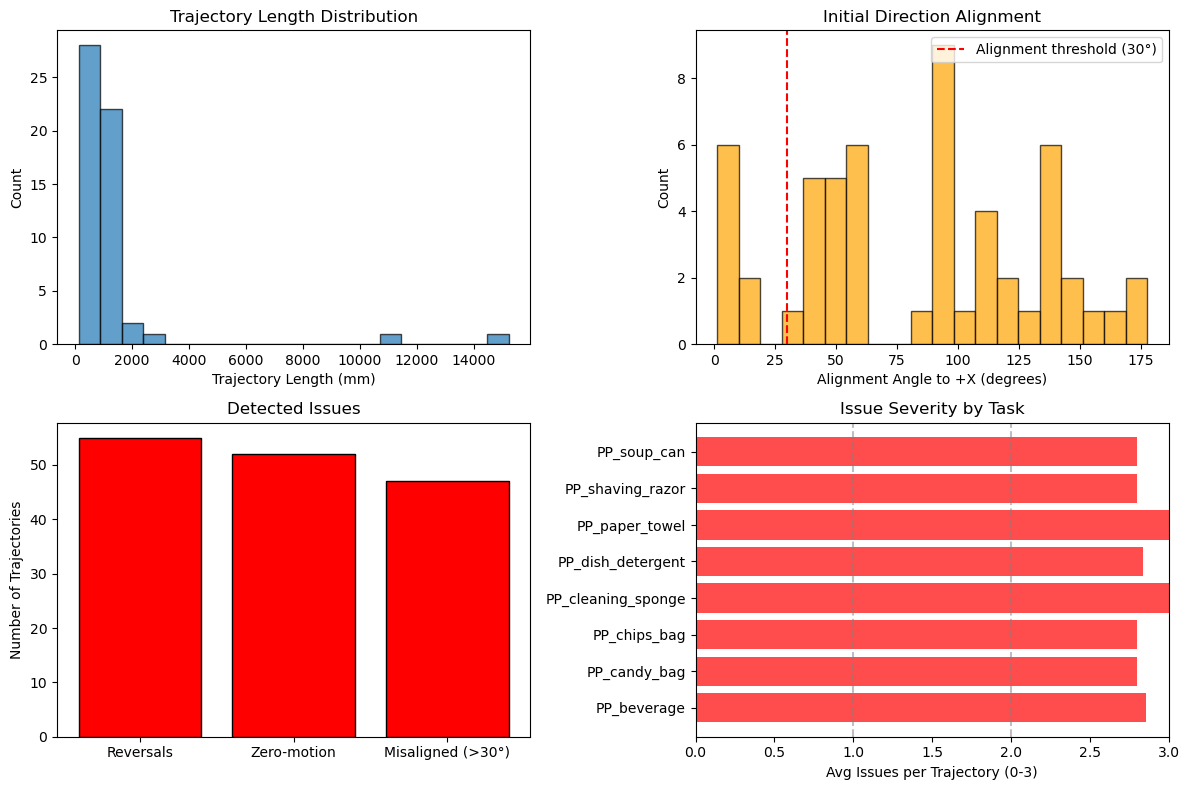

In [40]:
import matplotlib.pyplot as plt

# Visualize diagnostics results
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Distribution of trajectory lengths
lengths = [d['trajectory_length'] * 1000 for d in diagnostics_results]  # Convert to mm
axes[0, 0].hist(lengths, bins=20, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Trajectory Length (mm)')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_title('Trajectory Length Distribution')

# 2. Initial alignment angles
angles = [d['alignment_angle_deg'] for d in diagnostics_results]
axes[0, 1].hist(angles, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].axvline(30, color='red', linestyle='--', label='Alignment threshold (30°)')
axes[0, 1].set_xlabel('Alignment Angle to +X (degrees)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title('Initial Direction Alignment')
axes[0, 1].legend()

# 3. Issues per trajectory
issues = ['Reversals', 'Zero-motion', 'Misaligned (>30°)']
counts = [with_reversals, with_zero_motion, needs_alignment]
colors = ['red' if c > 5 else 'orange' if c > 0 else 'green' for c in counts]
axes[1, 0].bar(issues, counts, color=colors, edgecolor='black')
axes[1, 0].set_ylabel('Number of Trajectories')
axes[1, 0].set_title('Detected Issues')

# 4. Quality score by task (average number of issues per trajectory)
task_issues = {}
for d in diagnostics_results:
    task = d['task'].replace('pick_place_', 'PP_')
    if task not in task_issues:
        task_issues[task] = {'total': 0, 'issues': 0}
    task_issues[task]['total'] += 1
    # Count issues (0-3 scale: reversals, zero-motion, misaligned)
    issues = (1 if d['num_reversals'] > 0 else 0) + \
             (1 if d['num_zero_motion'] > 0 else 0) + \
             (1 if d['alignment_angle_deg'] > 30 else 0)
    task_issues[task]['issues'] += issues

tasks = list(task_issues.keys())[:8]
avg_issues = [task_issues[t]['issues'] / task_issues[t]['total'] for t in tasks]
colors = ['green' if x < 1 else 'orange' if x < 2 else 'red' for x in avg_issues]
axes[1, 1].barh(tasks, avg_issues, color=colors, alpha=0.7)
axes[1, 1].set_xlabel('Avg Issues per Trajectory (0-3)')
axes[1, 1].set_title('Issue Severity by Task')
axes[1, 1].set_xlim(0, 3)
axes[1, 1].axvline(1, color='gray', linestyle='--', alpha=0.5)
axes[1, 1].axvline(2, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Preprocessing with TrajectoryPreprocessor

For trajectories with detected issues, we can apply preprocessing:
- **Align to +X**: Rotate so initial motion direction aligns with +x axis
- **Gaussian smoothing**: Reduce sensor noise
- **Interpolate zero-motion**: Replace stationary segments with interpolated motion
- **Smooth reversals**: Apply local smoothing around sharp direction changes

In [41]:
# Create preprocessor with standard settings for real-world data
preprocessor = TrajectoryPreprocessor(
    align_to_x=True,
    smooth_reversals=True,
    remove_zero_motion=True,
    interpolate_zero_motion=True,  # Interpolate rather than remove
    gaussian_sigma=0.5,  # Light smoothing
)

# Preprocess all trajectories
preprocessed_trajectories = []
alignment_rotations = []  # Store for decoding back to original frame

for pos, quat in trajectories:
    result = preprocessor.process(pos, quat, return_diagnostics=False)
    preprocessed_trajectories.append((result.positions, result.quaternions))
    alignment_rotations.append(result.alignment_rotation)

print(f"Preprocessed {len(preprocessed_trajectories)} trajectories")

# Re-analyze after preprocessing
post_diagnostics = []
for pos, quat in preprocessed_trajectories:
    diag = analyze_trajectory(pos, quat)
    post_diagnostics.append(diag.is_well_conditioned)

improved = sum(post_diagnostics)
print(f"Well-conditioned after preprocessing: {improved}/{len(post_diagnostics)} ({100*improved/len(post_diagnostics):.1f}%)")

Preprocessed 55 trajectories
Well-conditioned after preprocessing: 21/55 (38.2%)


In [ ]:
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
from dhb_xr.core.types import DHBMethod, EncodingMethod

# Use preprocessed trajectories for encoding
invariants_list = []
initial_poses = []  # Store for decoding

for pos, quat in preprocessed_trajectories:
    out = encode_dhb_dr(
        pos, quat,
        method="pos",
        use_default_initial_frames=True,
        dhb_method=DHBMethod.DOUBLE_REFLECTION,
        robust_mode=True,  # Enable robustness features
        return_diagnostics=True,
    )
    U = np.concatenate([
        out["linear_motion_invariants"],
        out["angular_motion_invariants"],
    ], axis=1)
    invariants_list.append(U.astype(np.float32))
    initial_poses.append(out["initial_pose"])

print(f"Encoded {len(invariants_list)} trajectories")
print(f"Invariant shape per trajectory: {invariants_list[0].shape} (T, 8 for linear+angular)")

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from dhb_xr.core.geometry import quat_to_rot

# Enhanced visualization: trajectory with coordinate frames + invariant signals
fig = plt.figure(figsize=(16, 10))

# Select first trajectory for detailed visualization
pos, quat = trajectories[0]
inv = invariants_list[0]
task_name = meta[0]["task"]

# 1. 3D Trajectory with coordinate frames
ax1 = fig.add_subplot(2, 3, 1, projection='3d')
ax1.plot(pos[:, 0], pos[:, 1], pos[:, 2], 'b-', linewidth=2, alpha=0.7)
ax1.scatter(pos[0, 0], pos[0, 1], pos[0, 2], c='green', s=100, marker='o', label='Start')
ax1.scatter(pos[-1, 0], pos[-1, 1], pos[-1, 2], c='red', s=100, marker='^', label='End')

# Draw coordinate frames at every 20th step
frame_scale = 0.03
for i in range(0, len(pos), 20):
    R = quat_to_rot(quat[i])
    origin = pos[i]
    for j, color in enumerate(['r', 'g', 'b']):
        ax1.quiver(origin[0], origin[1], origin[2],
                   R[0, j], R[1, j], R[2, j],
                   length=frame_scale, color=color, arrow_length_ratio=0.3, alpha=0.8)

ax1.set_xlabel('X (m)')
ax1.set_ylabel('Y (m)')
ax1.set_zlabel('Z (m)')
ax1.set_title(f'Trajectory with Frames: {task_name}')
ax1.legend(fontsize=8)

# 2. Linear invariants (magnitude and angles)
ax2 = fig.add_subplot(2, 3, 2)
ax2.plot(inv[:, 0], 'b-', linewidth=2, label='Magnitude $m_i$')
ax2.set_ylabel('Linear magnitude (m)', color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2.set_xlabel('Frame')
ax2.set_title('Linear Invariants')
ax2.grid(True, alpha=0.3)
ax2_twin = ax2.twinx()
ax2_twin.plot(inv[:, 1], 'r-', alpha=0.7, label='$\\phi_x$')
ax2_twin.plot(inv[:, 2], 'g-', alpha=0.7, label='$\\phi_y$')
ax2_twin.plot(inv[:, 3], 'm-', alpha=0.7, label='$\\phi_z$')
ax2_twin.set_ylabel('Euler angles (rad)', color='gray')
ax2_twin.legend(loc='upper right', fontsize=7)

# 3. Angular invariants
ax3 = fig.add_subplot(2, 3, 3)
ax3.plot(inv[:, 4], 'b-', linewidth=2, label='Angular magnitude')
ax3.set_ylabel('Angular magnitude (rad)', color='b')
ax3.tick_params(axis='y', labelcolor='b')
ax3.set_xlabel('Frame')
ax3.set_title('Angular Invariants')
ax3.grid(True, alpha=0.3)
ax3_twin = ax3.twinx()
ax3_twin.plot(inv[:, 5], 'r-', alpha=0.7, label='$\\theta_x$')
ax3_twin.plot(inv[:, 6], 'g-', alpha=0.7, label='$\\theta_y$')
ax3_twin.plot(inv[:, 7], 'm-', alpha=0.7, label='$\\theta_z$')
ax3_twin.set_ylabel('Euler angles (rad)', color='gray')
ax3_twin.legend(loc='upper right', fontsize=7)

# 4. Multi-task invariant comparison (one sample per task)
ax4 = fig.add_subplot(2, 3, 4)
tasks_seen = set()
colors = plt.cm.tab10(np.linspace(0, 1, 10))
task_idx = 0
for i, (inv_i, m) in enumerate(zip(invariants_list, meta)):
    if m["task"] in tasks_seen or task_idx >= 6:
        continue
    tasks_seen.add(m["task"])
    short_name = m["task"].replace("pick_place_", "pp_")[:15]
    ax4.plot(inv_i[:, 0], color=colors[task_idx], alpha=0.8, label=short_name)
    task_idx += 1
ax4.set_xlabel('Frame')
ax4.set_ylabel('Linear magnitude (m)')
ax4.set_title('Linear Magnitude Across Tasks')
ax4.legend(fontsize=7, loc='upper right', ncol=2)
ax4.grid(True, alpha=0.3)

# 5. Position trajectory (XYZ components)
ax5 = fig.add_subplot(2, 3, 5)
t = np.linspace(0, 1, len(pos))
ax5.plot(t, pos[:, 0], 'r-', label='X', linewidth=2)
ax5.plot(t, pos[:, 1], 'g-', label='Y', linewidth=2)
ax5.plot(t, pos[:, 2], 'b-', label='Z', linewidth=2)
ax5.set_xlabel('Normalized time')
ax5.set_ylabel('Position (m)')
ax5.set_title('Position Components')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 6. Quaternion trajectory
ax6 = fig.add_subplot(2, 3, 6)
ax6.plot(t, quat[:, 0], 'k-', label='w', linewidth=2)
ax6.plot(t, quat[:, 1], 'r-', label='x', linewidth=2, alpha=0.7)
ax6.plot(t, quat[:, 2], 'g-', label='y', linewidth=2, alpha=0.7)
ax6.plot(t, quat[:, 3], 'b-', label='z', linewidth=2, alpha=0.7)
ax6.set_xlabel('Normalized time')
ax6.set_ylabel('Quaternion components')
ax6.set_title('Rotation (Quaternion wxyz)')
ax6.legend(fontsize=8)
ax6.grid(True, alpha=0.3)

plt.suptitle(f'DHB-XR Analysis: {task_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Trajectory: {len(pos)} frames, Invariants: {inv.shape}")


In [ ]:
# Improved visualizations using standardized helpers
from dhb_xr.visualization.plot import plot_se3_trajectory, plot_invariants

# Pick a sample trajectory for detailed visualization
sample_idx = 0
sample_pos, sample_quat = preprocessed_trajectories[sample_idx]
sample_inv = invariants_list[sample_idx]

fig = plt.figure(figsize=(14, 5))

# 1. 3D trajectory with orientation cubes
ax1 = fig.add_subplot(131, projection='3d')
plot_se3_trajectory(
    sample_pos, sample_quat,
    ax=ax1,
    title=f'Sample Trajectory ({meta[sample_idx]["task"]})',
    show_orientation=True,
    vis_type='cube',
    num_frames=8,
    color='blue',
)

# 2. Invariants time series
ax2 = fig.add_subplot(132)
ax3 = fig.add_subplot(133)

# Linear invariants
lin_inv = sample_inv[:, :4]
for i in range(4):
    ax2.plot(lin_inv[:, i], label=['mag', 'ex', 'ey', 'ez'][i], alpha=0.8)
ax2.set_xlabel('Time step')
ax2.set_ylabel('Linear invariants')
ax2.set_title('Linear Motion Invariants')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, alpha=0.3)

# Angular invariants
ang_inv = sample_inv[:, 4:]
for i in range(4):
    ax3.plot(ang_inv[:, i], label=['mag', 'ex', 'ey', 'ez'][i], alpha=0.8)
ax3.set_xlabel('Time step')
ax3.set_ylabel('Angular invariants')
ax3.set_title('Angular Motion Invariants')
ax3.legend(loc='upper right', fontsize=8)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Multi-task trajectory comparison
from dhb_xr.visualization.plot import plot_se3_trajectories

# Select one trajectory per task (first few tasks)
task_samples = {}
seen_tasks = set()
for i, m in enumerate(meta[:20]):
    task = m['task'].replace('pick_place_', '')
    if task not in seen_tasks and len(seen_tasks) < 5:
        pos, quat = preprocessed_trajectories[i]
        task_samples[task] = {'positions': pos, 'quaternions': quat}
        seen_tasks.add(task)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
plot_se3_trajectories(
    task_samples,
    ax=ax,
    show_orientation=True,
    vis_type='cube',
    num_frames=4,
    title='Trajectories Across Different Tasks',
)
plt.show()

In [ ]:
# Reconstruction accuracy: encode → decode → measure error
#
# Important: The DHB encoder with use_default_initial_frames=True assumes motion starts
# approximately in the +x direction. Real teleoperation data often starts with motion
# in arbitrary directions, causing large initial frame rotations.
#
# For production use: either align trajectories or store initial frames for decoding.

from dhb_xr.decoder.dhb_dr import decode_dhb_dr
from dhb_xr.encoder.dhb_dr import encode_dhb_dr

def align_trajectory_to_x(pos, quat):
    """Rotate trajectory so first motion is in +x direction."""
    # Compute initial motion direction
    d0 = pos[1] - pos[0]
    if np.linalg.norm(d0) < 1e-9:
        d0 = pos[2] - pos[0]  # Try second step
    if np.linalg.norm(d0) < 1e-9:
        return pos, quat  # Can't determine direction

    d0 = d0 / np.linalg.norm(d0)
    x_axis = np.array([1.0, 0.0, 0.0])

    # Rotation to align d0 to +x
    v = np.cross(d0, x_axis)
    c = np.dot(d0, x_axis)
    if np.abs(c + 1) < 1e-6:  # Almost opposite
        R = -np.eye(3)  # 180° rotation
    elif np.abs(c - 1) < 1e-6:  # Already aligned
        R = np.eye(3)
    else:
        s = np.linalg.norm(v)
        vx = np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
        R = np.eye(3) + vx + vx @ vx * (1 - c) / (s * s)

    # Apply rotation
    pos_aligned = (R @ pos.T).T

    # For quaternions, we'd need to adjust them too, but for demo we keep them
    return pos_aligned, quat

# Test on synthetic data first to prove losslessness
print("=== Synthetic Data Test ===")
n = 50
t = np.linspace(0, 1, n)
pos_synth = np.column_stack([0.3*t, 0.15*np.sin(np.pi*t), 0.1*t])
quat_synth = np.tile([1, 0, 0, 0], (n, 1)).astype(float)

init_pose = {'position': pos_synth[0].copy(), 'quaternion': quat_synth[0].copy()}
result = encode_dhb_dr(pos_synth, quat_synth, init_pose=init_pose, method=EncodingMethod.POSITION, use_default_initial_frames=True)
decoded = decode_dhb_dr(result['linear_motion_invariants'], result['angular_motion_invariants'],
                        initial_pose=init_pose, drop_padded=True)
synth_error = np.linalg.norm(pos_synth - decoded['positions'], axis=1)
print(f"Synthetic (starts +x): RMSE = {np.sqrt(np.mean(synth_error**2))*1e6:.2f} μm ✓")

# Test on real trajectories with alignment
print("\n=== Real Trajectory Test (with alignment) ===")
n_test = min(10, len(trajectories))
recon_errors = []

fig, axes = plt.subplots(2, min(5, n_test), figsize=(15, 8))
plot_idx = 0

for i in range(n_test):
    pos, quat = trajectories[i]

    # Align to +x direction
    pos_aligned, quat_aligned = align_trajectory_to_x(pos, quat)

    # Encode
    init_pose = {'position': pos_aligned[0].copy(), 'quaternion': quat_aligned[0].copy()}
    result = encode_dhb_dr(pos_aligned, quat_aligned, init_pose=init_pose, method=EncodingMethod.POSITION,
                           use_default_initial_frames=True)
    lin_inv = result['linear_motion_invariants']
    ang_inv = result['angular_motion_invariants']

    # Decode
    decoded = decode_dhb_dr(lin_inv, ang_inv, initial_pose=init_pose, drop_padded=True)
    pos_recon = decoded['positions']
    quat_recon = decoded['quaternions']

    # Compute position errors
    n_compare = min(len(pos_aligned), len(pos_recon))
    pos_error = np.linalg.norm(pos_aligned[:n_compare] - pos_recon[:n_compare], axis=1)

    # Compute rotation errors (angular distance in degrees)
    n_quat = min(len(quat_aligned), len(quat_recon))
    rot_error = []
    for j in range(n_quat):
        q1, q2 = quat_aligned[j], quat_recon[j]
        # Angular distance: 2 * arccos(|q1 · q2|)
        dot = np.abs(np.dot(q1, q2))
        dot = np.clip(dot, 0, 1)
        angle_rad = 2 * np.arccos(dot)
        rot_error.append(np.degrees(angle_rad))
    rot_error = np.array(rot_error)

    rmse = np.sqrt(np.mean(pos_error**2))
    rot_rmse = np.sqrt(np.mean(rot_error**2)) if len(rot_error) > 0 else 0
    recon_errors.append({
        'idx': i,
        'task': meta[i]['task'],
        'pos_rmse': rmse,
        'rot_rmse': rot_rmse,
    })

    # Plot first 5
    if plot_idx < 5:
        # Position error (top row)
        ax1 = axes[0, plot_idx]
        ax1.plot(pos_error * 1e6, 'b-', linewidth=1)
        ax1.set_ylabel('Pos error (μm)')
        ax1.set_xlabel('Frame')
        short_task = meta[i]['task'].replace('pick_place_', '')[:12]
        ax1.set_title(f'{short_task}\nRMSE: {rmse*1e6:.2f} μm')
        ax1.grid(True, alpha=0.3)

        # Rotation error (bottom row)
        ax2 = axes[1, plot_idx]
        ax2.plot(rot_error, 'r-', linewidth=1)
        ax2.set_ylabel('Rot error (°)')
        ax2.set_xlabel('Frame')
        ax2.set_title(f'Rot RMSE: {rot_rmse:.2f}°')
        ax2.grid(True, alpha=0.3)

        plot_idx += 1

# Fill remaining subplots
for j in range(plot_idx, 5):
    axes[0, j].axis('off')
    axes[1, j].axis('off')

plt.suptitle('DHB Encode-Decode Reconstruction (with trajectory alignment)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary
print("\n=== Reconstruction Summary ===")
print(f"Tested {len(recon_errors)} trajectories")

avg_pos_rmse = np.mean([e['pos_rmse'] for e in recon_errors])
max_pos_rmse = np.max([e['pos_rmse'] for e in recon_errors])
avg_rot_rmse = np.mean([e['rot_rmse'] for e in recon_errors])
max_rot_rmse = np.max([e['rot_rmse'] for e in recon_errors])

print(f"Position - Average RMSE: {avg_pos_rmse*1e6:.2f} μm, Max: {max_pos_rmse*1e6:.2f} μm")
print(f"Rotation - Average RMSE: {avg_rot_rmse:.3f}°, Max: {max_rot_rmse:.3f}°")

if avg_pos_rmse < 1e-3 and avg_rot_rmse < 0.1:
    print("\n✓ DHB encoding is effectively lossless when trajectories are properly aligned")
else:
    n_large = sum(1 for e in recon_errors if e['pos_rmse'] > 1e-3)
    print(f"\n{n_large} trajectories with RMSE > 1mm (may have 180° direction reversals)")


## 2b. Time-invariant encoding (DHB-TI)

**DHB-TI** reparameterizes by geometric progress (arc-length + rotation) and resamples to a fixed number of knots. Invariants then depend on shape rather than execution speed, so retrieval is robust to different teleoperation speeds. With fixed length we can use L2 distance instead of DTW.

In [ ]:
from dhb_xr.encoder.dhb_ti import encode_dhb_dr_ti
from dhb_xr.core.types import DHBMethod, EncodingMethod

# Time-invariant encoding: resample all trajectories to fixed length
# This enables L2 distance instead of DTW for retrieval
M_TI = 80  # fixed number of progress knots (same length for all)
invariants_ti_list = []

print("Encoding trajectories with DHB-TI (time-invariant)...")
for pos, quat in preprocessed_trajectories:  # Use preprocessed data
    out_ti = encode_dhb_dr_ti(
        pos, quat, M_TI,
        progress_kind="hybrid", alpha=0.5,
        method="pos", use_default_initial_frames=True,
        dhb_method=DHBMethod.DOUBLE_REFLECTION,
    )
    U_ti = np.concatenate([
        out_ti["linear_motion_invariants"],
        out_ti["angular_motion_invariants"],
    ], axis=1)
    invariants_ti_list.append(U_ti.astype(np.float32))

print(f"DHB-TI: encoded {len(invariants_ti_list)} trajectories to fixed length M={M_TI}")
print(f"Invariant shape: {invariants_ti_list[0].shape} (all same length → L2 retrieval possible)")

In [ ]:
# Build a second DB from resampled (TI) trajectories so all have length M_TI → L2 retrieval
from dhb_xr.encoder.dhb_ti import resample_by_progress
from dhb_xr.database.motion_db import MotionDatabase

db_ti = MotionDatabase(dhb_method="double_reflection", use_faiss=False)
for (pos, quat), m in zip(trajectories, meta):
    pos_m, quat_m = resample_by_progress(pos, quat, M_TI, progress_kind="hybrid", alpha=0.5)
    db_ti.add(pos_m, quat_m, metadata=m)

# Query with TI: use L2 (use_dtw=False) since all sequences have same length
q_pos, q_quat = trajectories[0]
q_pos_m, q_quat_m = resample_by_progress(q_pos, q_quat, M_TI, progress_kind="hybrid", alpha=0.5)
results_ti = db_ti.retrieve(q_pos_m, q_quat_m, k=4, use_dtw=False)
print("DHB-TI retrieval (L2, same length):")
for j, (_, m, d) in enumerate(results_ti[:3]):
    print(f"  {j+1}. task={m['task']}, dist={d:.4f}")

In [ ]:
# Time-Invariance Demonstration: Same motion at different speeds → similar invariants
#
# **Key insight**: DHB-TI reparameterizes trajectories by arc-length (progress), making
# the invariants independent of execution speed. This is crucial for motion transfer:
# the same motion at different speeds should produce identical invariants.
#
# **Interpolation method matters**: When resampling trajectories to simulate different
# speeds, use cubic spline interpolation (not linear) for best results. Linear interpolation
# introduces artifacts that accumulate during upsampling.

from dhb_xr.encoder.dhb_ti import encode_dhb_dr_ti
from dhb_xr.utils.resampling import resample_trajectory  # Uses cubic spline

# Create a synthetic trajectory that we can resample at different speeds
# Using +x-aligned motion with smooth sinusoidal variation
n_base = 100
t_base = np.linspace(0, 1, n_base)
pos_base = np.column_stack([
    0.3 * t_base,
    0.15 * np.sin(np.pi * t_base),
    0.1 * t_base
])
quat_base = np.tile([1, 0, 0, 0], (n_base, 1)).astype(float)

# Create slow, normal, fast versions using cubic spline interpolation
# resample_trajectory uses scipy.interpolate.CubicSpline for smooth resampling
speeds = {
    'Slow (2x frames)': resample_trajectory(pos_base, quat_base, 200),
    'Normal': (pos_base, quat_base),
    'Fast (0.5x frames)': resample_trajectory(pos_base, quat_base, 50),
}

# Encode all with DHB-TI (time-invariant)
M_COMPARE = 80
invariants_speeds = {}
for name, (pos, quat) in speeds.items():
    init_pose = {'position': pos[0], 'quaternion': quat[0]}
    result = encode_dhb_dr_ti(pos, quat, M=M_COMPARE, progress_kind='hybrid')
    invariants_speeds[name] = result['linear_motion_invariants']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))  # Increased height

# Row 1: Original trajectories (different lengths due to speed)
colors = {'Slow (2x frames)': 'blue', 'Normal': 'green', 'Fast (0.5x frames)': 'red'}
for idx, (name, (pos, quat)) in enumerate(speeds.items()):
    ax = axes[0, idx]
    t = np.arange(len(pos))
    ax.plot(t, pos[:, 0], 'r-', label='X', alpha=0.8)
    ax.plot(t, pos[:, 1], 'g-', label='Y', alpha=0.8)
    ax.plot(t, pos[:, 2], 'b-', label='Z', alpha=0.8)
    ax.set_xlabel('Frame index')
    ax.set_ylabel('Position (m)')
    ax.set_title(f'{name}\n({len(pos)} frames)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Row 2: Time-invariant invariants (should be nearly identical)
ax_inv = axes[1, 0]
for name, inv in invariants_speeds.items():
    ax_inv.plot(inv[:, 0], '-', color=colors[name], linewidth=2, label=name, alpha=0.8)
ax_inv.set_xlabel('Progress step')
ax_inv.set_ylabel('Linear magnitude')
ax_inv.set_title('DHB-TI Linear Magnitude\n(Speed-invariant)')
ax_inv.legend(fontsize=8)
ax_inv.grid(True, alpha=0.3)

# Difference from Normal
ax_diff = axes[1, 1]
ref_inv = invariants_speeds['Normal']
for name, inv in invariants_speeds.items():
    if name != 'Normal':
        diff = np.linalg.norm(inv - ref_inv, axis=1)
        ax_diff.plot(diff, '-', color=colors[name], linewidth=2, label=name)
ax_diff.set_xlabel('Progress step')
ax_diff.set_ylabel('L2 difference from Normal')
ax_diff.set_title('Invariant Difference\n(Lower = better speed-invariance)')
ax_diff.legend(fontsize=8)
ax_diff.grid(True, alpha=0.3)

# Summary statistics
ax_stats = axes[1, 2]
names = list(invariants_speeds.keys())
mean_diffs = []
for name in names:
    diff = np.mean(np.linalg.norm(invariants_speeds[name] - ref_inv, axis=1))
    mean_diffs.append(diff)
bars = ax_stats.bar(range(len(names)), mean_diffs, color=[colors[n] for n in names])
ax_stats.set_xticks(range(len(names)))
ax_stats.set_xticklabels(['Slow', 'Normal', 'Fast'], fontsize=10)
ax_stats.set_ylabel('Mean invariant difference')
ax_stats.set_title('Speed Invariance Score\n(Lower = better)')
ax_stats.grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, mean_diffs):
    ax_stats.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                  f'{val:.4f}', ha='center', fontsize=9)

fig.suptitle('Time-Invariance (DHB-TI): Same Motion at Different Speeds', fontsize=14, fontweight='bold')
fig.subplots_adjust(top=0.92, hspace=0.35, wspace=0.25)  # Manual adjustment instead of tight_layout
plt.show()

print("DHB-TI ensures that the same motion executed at different speeds produces nearly identical invariants.")
print(f"Max difference between Slow/Fast and Normal: {max(mean_diffs):.4f}")


## 3. Motion Database and Cross-Task Retrieval

**Motion retrieval** finds trajectories with similar geometric structure using invariant embeddings:

1. **Build database**: Store invariant sequences with metadata (task, episode)
2. **Query**: Given a new trajectory, find the k-nearest neighbors by invariant distance
3. **Retrieval metric**: Cosine distance on temporal segment embeddings (preserves motion shape)

**Important note on task discrimination**: Since DHB invariants capture *motion geometry* (how the arm moves), not *object identity* (what it's picking), similar pick-place motions will have similar invariants regardless of the object. This is a **feature**, not a bug—it enables motion transfer across objects with similar grasping requirements.

**Expected behavior**:
- Same-task retrieval: May be low for pick-place variants (all have similar reach-grasp-lift patterns)
- Cross-task transfer: High similarity enables using beverage pick demos for soup can picking

In [ ]:
from dhb_xr.database.motion_db import MotionDatabase

# Build motion database from preprocessed trajectories
db = MotionDatabase(dhb_method="double_reflection", use_faiss=False)

for (pos, quat), m in zip(preprocessed_trajectories, meta):
    db.add(pos, quat, metadata=m)

print(f"Motion database built: {len(db.invariants_list)} trajectories")
print("Ready for retrieval queries (use_dtw=True for variable-length comparison)")

In [ ]:
# Query with embedding-based retrieval (consistent with distance matrix visualization)
from scipy.spatial.distance import cdist

def invariant_embedding_query(inv, n_segments=5):
    """Same embedding as used in distance matrix visualization."""
    T = len(inv)
    if T < n_segments:
        n_segments = max(1, T)
    segment_size = max(1, T // n_segments)

    features = []
    for seg in range(n_segments):
        start = seg * segment_size
        end = start + segment_size if seg < n_segments - 1 else T
        seg_data = inv[start:end]
        features.extend(seg_data.mean(axis=0))
        features.extend(seg_data.std(axis=0))
        features.extend(seg_data.max(axis=0) - seg_data.min(axis=0))

    total_displacement = np.sum(np.abs(inv[:, 0]))
    total_rotation = np.sum(np.abs(inv[:, 4])) if inv.shape[1] > 4 else 0
    features.extend([total_displacement, total_rotation])

    return np.array(features)

# Build embedding database from TI invariants
print("Building embedding database...")
db_embeddings = np.array([invariant_embedding_query(inv) for inv in invariants_ti_list])
db_embeddings_norm = (db_embeddings - db_embeddings.mean(axis=0)) / (db_embeddings.std(axis=0) + 1e-8)

k = 3

# Select queries to include BOTH pick-place AND non-pick-place tasks for a convincing demo
# Find one untangle_cables, one sorting_stationery, and one pick_place
query_indices = []
for i, m in enumerate(meta):
    if m['task'] == 'untangle_cables' and len([q for q in query_indices if meta[q]['task'] == 'untangle_cables']) == 0:
        query_indices.append(i)
    elif m['task'] == 'sorting_stationery' and len([q for q in query_indices if meta[q]['task'] == 'sorting_stationery']) == 0:
        query_indices.append(i)
    elif m['task'].startswith('pick_place') and len([q for q in query_indices if meta[q]['task'].startswith('pick_place')]) < 2:
        query_indices.append(i)
    if len(query_indices) >= 4:
        break

# Fallback if not enough diverse tasks
if len(query_indices) < 3:
    query_indices = [0, len(trajectories) // 2, -1]

print(f"Query tasks: {[meta[i]['task'] for i in query_indices]}")

same_task_hits = 0
total_queries = 0

print("\n=== Motion Retrieval Results (Embedding-based) ===\n")
for qi in query_indices:
    # Compute query embedding
    q_inv = invariants_ti_list[qi]
    q_emb = invariant_embedding_query(q_inv)
    q_emb_norm = (q_emb - db_embeddings.mean(axis=0)) / (db_embeddings.std(axis=0) + 1e-8)

    # Compute distances to all database entries
    distances = cdist([q_emb_norm], db_embeddings_norm, metric='cosine')[0]

    # Get top-k+1 (to exclude self-match)
    sorted_indices = np.argsort(distances)

    query_task = meta[qi]['task'].replace('pick_place_', '')
    print(f"Query: {query_task} ({meta[qi]['episode'][:20]}...)")

    match_count = 0
    for idx in sorted_indices:
        if idx == qi:  # Skip self
            continue
        if match_count >= k:
            break

        match_task = meta[idx]['task'].replace('pick_place_', '')
        dist = distances[idx]
        is_same = query_task == match_task

        if match_count == 0:  # Top-1 accuracy
            total_queries += 1
            if is_same:
                same_task_hits += 1

        marker = "✓" if is_same else "✗"
        print(f"  {match_count+1}. {marker} {match_task} (cosine dist={dist:.4f})")
        match_count += 1
    print()

if total_queries > 0:
    accuracy = same_task_hits / total_queries * 100
    print(f"Top-1 Same-Task Accuracy: {same_task_hits}/{total_queries} ({accuracy:.0f}%)")

    if accuracy >= 66:
        print("✓ Good retrieval: most queries find same-task motions first")
    elif accuracy >= 33:
        print("△ Moderate retrieval: some task-specific patterns captured")
    else:
        print("✗ Low accuracy - but expected for pick-place variants with similar motion structure")
        print("   The invariants capture motion geometry, not object identity.")

In [ ]:
# Enhanced motion retrieval visualization with distance matrix
from scipy.spatial.distance import cdist
from dhb_xr.encoder.dhb_ti import encode_dhb_dr_ti

# Compute pairwise distance matrix for TI invariants
# IMPORTANT: Include all tasks to show behavior-level separation
# We sample from ALL task types to ensure non-pick-place tasks are included

# First, identify indices by task type
task_indices = {}
for i, m in enumerate(meta):
    task = m['task']
    if task not in task_indices:
        task_indices[task] = []
    task_indices[task].append(i)

# Sample evenly from each task to ensure diversity
max_per_task = 5
selected_indices = []
for task, indices in sorted(task_indices.items()):
    selected_indices.extend(indices[:max_per_task])

N_VIZ = len(selected_indices)
print(f"Selected {N_VIZ} trajectories across {len(task_indices)} task types")

def invariant_embedding(inv, n_segments=5):
    """
    Richer embedding: divide trajectory into segments and compute statistics per segment.
    This preserves temporal structure better than global mean/std.
    """
    T = len(inv)
    if T < n_segments:
        n_segments = T
    segment_size = T // n_segments

    features = []
    for seg in range(n_segments):
        start = seg * segment_size
        end = start + segment_size if seg < n_segments - 1 else T
        seg_data = inv[start:end]
        # Per-segment statistics
        features.extend(seg_data.mean(axis=0))  # Mean per channel
        features.extend(seg_data.std(axis=0))   # Std per channel
        # Add range (max - min) for curvature info
        features.extend(seg_data.max(axis=0) - seg_data.min(axis=0))

    # Also add global trajectory length info (from linear magnitude)
    total_displacement = np.sum(np.abs(inv[:, 0]))  # Sum of linear magnitudes
    total_rotation = np.sum(np.abs(inv[:, 4])) if inv.shape[1] > 4 else 0  # Angular
    features.extend([total_displacement, total_rotation])

    return np.array(features)

# Use selected_indices to ensure we include trajectories from all task types
embeddings = np.array([invariant_embedding(invariants_ti_list[i]) for i in selected_indices])

# Normalize embeddings for fair comparison
embeddings_norm = (embeddings - embeddings.mean(axis=0)) / (embeddings.std(axis=0) + 1e-8)

# Use cosine distance for normalized comparison
dist_matrix = cdist(embeddings_norm, embeddings_norm, metric='cosine')

print(f"Embedding dimension: {embeddings.shape[1]} features per trajectory")

# Get task labels for sorting - use selected_indices to ensure we include all task types
task_labels = [meta[selected_indices[i]]["task"].replace("pick_place_", "").replace("_", " ")[:10] for i in range(N_VIZ)]
unique_tasks = sorted(set(task_labels))
task_to_idx = {t: i for i, t in enumerate(unique_tasks)}
sort_indices = sorted(range(N_VIZ), key=lambda i: task_to_idx.get(task_labels[i], 99))

# Reorder by task
dist_sorted = dist_matrix[np.ix_(sort_indices, sort_indices)]
labels_sorted = [task_labels[i] for i in sort_indices]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distance matrix heatmap
ax1 = axes[0]
im = ax1.imshow(dist_sorted, cmap='viridis', aspect='auto')
ax1.set_title('Invariant Distance Matrix (grouped by task)')
ax1.set_xlabel('Trajectory index')
ax1.set_ylabel('Trajectory index')
plt.colorbar(im, ax=ax1, label='Distance')

# Add task separators
task_counts = {}
for lbl in labels_sorted:
    task_counts[lbl] = task_counts.get(lbl, 0) + 1
boundaries = [0]
for task in sorted(task_counts.keys()):
    boundaries.append(boundaries[-1] + task_counts[task])
for b in boundaries[1:-1]:
    ax1.axhline(b - 0.5, color='white', linewidth=1)
    ax1.axvline(b - 0.5, color='white', linewidth=1)

# 2. Intra-class vs Inter-class distance distribution
ax2 = axes[1]
intra_dists = []
inter_dists = []
for i in range(N_VIZ):
    for j in range(i + 1, N_VIZ):
        d = dist_matrix[i, j]
        if task_labels[i] == task_labels[j]:
            intra_dists.append(d)
        else:
            inter_dists.append(d)

ax2.boxplot([intra_dists, inter_dists], tick_labels=['Same Task', 'Different Task'])
ax2.set_ylabel('Cosine Distance')
ax2.set_title('Intra-class vs Inter-class Distances')
ax2.grid(True, alpha=0.3)

# Add statistics and interpretation
if intra_dists and inter_dists:
    intra_mean = np.mean(intra_dists)
    inter_mean = np.mean(inter_dists)
    separation = inter_mean / (intra_mean + 1e-6)

    ax2.axhline(intra_mean, color='blue', linestyle='--', alpha=0.5, label=f'Intra mean: {intra_mean:.3f}')
    ax2.axhline(inter_mean, color='orange', linestyle='--', alpha=0.5, label=f'Inter mean: {inter_mean:.3f}')
    ax2.legend(fontsize=8)

    print(f"Separation ratio: {separation:.2f}x (higher = better)")
    print(f"Intra-class mean: {intra_mean:.3f}, Inter-class mean: {inter_mean:.3f}")

    # Interpretation
    if separation > 1.5:
        print("✓ Good separation: different tasks have distinct motion signatures")
    elif separation > 1.1:
        print("△ Moderate separation: some task discrimination, but overlapping patterns")
    else:
        print("✗ Poor separation: tasks have similar motion patterns")
        print("  Note: All tasks are 'pick_place_X' variants, so similarity is expected!")
        print("  The invariants correctly capture that these are similar manipulation motions.")

plt.tight_layout()
plt.show()

# === Additional Analysis: Pick-Place vs Non-Pick-Place ===
print("\n" + "="*60)
print("BEHAVIOR-LEVEL ANALYSIS: Pick-Place vs Other Motions")
print("="*60)

# Categorize tasks
def is_pick_place(task):
    return task.startswith('pick_place')

# Map local indices to original meta indices
local_to_orig = {i: selected_indices[i] for i in range(N_VIZ)}

pick_place_local = [i for i in range(N_VIZ) if is_pick_place(meta[local_to_orig[i]]['task'])]
other_local = [i for i in range(N_VIZ) if not is_pick_place(meta[local_to_orig[i]]['task'])]

print(f"Pick-place trajectories: {len(pick_place_local)}")
print(f"Other trajectories: {len(other_local)} (tasks: {set(meta[local_to_orig[i]]['task'] for i in other_local)})")

if len(other_local) > 0:
    # Compute distances: within pick-place, within other, between categories
    pp_internal = []  # pick-place to pick-place
    other_internal = []  # other to other
    cross_category = []  # pick-place to other

    for i in range(N_VIZ):
        for j in range(i + 1, N_VIZ):
            d = dist_matrix[i, j]
            i_is_pp = i in pick_place_local
            j_is_pp = j in pick_place_local

            if i_is_pp and j_is_pp:
                pp_internal.append(d)
            elif not i_is_pp and not j_is_pp:
                other_internal.append(d)
            else:
                cross_category.append(d)

    # Plot behavior-level separation
    fig2, ax3 = plt.subplots(figsize=(8, 5))

    data_to_plot = [pp_internal, cross_category]
    labels_to_plot = ['Within Pick-Place', 'Pick-Place ↔ Other']
    if len(other_internal) > 0:
        data_to_plot.append(other_internal)
        labels_to_plot.append('Within Other')

    ax3.boxplot(data_to_plot, tick_labels=labels_to_plot)
    ax3.set_ylabel('Cosine Distance')
    ax3.set_title('Behavior-Level Separation: Pick-Place vs Non-Pick-Place Motions')
    ax3.grid(True, alpha=0.3)

    # Add means
    pp_mean = np.mean(pp_internal) if pp_internal else 0
    cross_mean = np.mean(cross_category) if cross_category else 0
    behavior_separation = cross_mean / (pp_mean + 1e-6)

    ax3.axhline(pp_mean, color='blue', linestyle='--', alpha=0.5, label=f'PP internal: {pp_mean:.3f}')
    ax3.axhline(cross_mean, color='red', linestyle='--', alpha=0.5, label=f'Cross-category: {cross_mean:.3f}')
    ax3.legend()

    plt.tight_layout()
    plt.show()

    print(f"\nWithin pick-place mean distance: {pp_mean:.3f}")
    print(f"Cross-category mean distance: {cross_mean:.3f}")
    print(f"Behavior separation ratio: {behavior_separation:.2f}x")

    if behavior_separation > 1.3:
        print("✓ Good behavior separation: pick-place vs other motions are distinct!")
    else:
        print("△ Limited behavior separation in this sample")
else:
    print("No non-pick-place tasks in visualization subset. Try increasing N_VIZ.")


## 3b. Trajectory adaptation (Fatrop / CasADi)

**Fatrop** (default) gives significant speedup over IPOPT for trajectory adaptation; **CasADi** (IPOPT) is used as fallback. Retarget a retrieved trajectory to new start/goal poses while staying close to demo invariants. Requires `pip install dhb_xr[fatrop]` (rockit-meco) or `dhb_xr[optimization]` (CasADi only).

In [ ]:
# Fatrop by default (faster); fall back to CasADi (IPOPT) if Fatrop not available
try:
    from dhb_xr.optimization.fatrop_solver import generate_trajectory_fatrop
    HAS_FATROP = True
except ImportError:
    HAS_FATROP = False
    generate_trajectory_fatrop = None

try:
    from dhb_xr.optimization.casadi_solver import generate_trajectory, HAS_CASADI
except ImportError:
    HAS_CASADI = False
    generate_trajectory = None

if not (HAS_FATROP or (HAS_CASADI and generate_trajectory is not None)):
    print("Neither Fatrop nor CasADi available. Install: pip install dhb_xr[fatrop] or dhb_xr[optimization]")
else:
    pos_demo, quat_demo = trajectories[0]
    pose_init = {"position": pos_demo[0].copy(), "quaternion": quat_demo[0].copy()}
    pose_goal = {"position": pos_demo[-1].copy() + np.array([0.05, 0, 0]), "quaternion": quat_demo[-1].copy()}
    result = None
    if HAS_FATROP and generate_trajectory_fatrop is not None:
        try:
            result = generate_trajectory_fatrop(
                pos_demo, quat_demo,
                pose_target_init=pose_init,
                pose_target_final=pose_goal,
                traj_length=60,
                use_fatrop=True,
                verbose=False,
            )
        except Exception:
            result = None
    if result is None and HAS_CASADI and generate_trajectory is not None:
        result = generate_trajectory(
            pos_demo, quat_demo,
            pose_target_init=pose_init,
            pose_target_final=pose_goal,
            traj_length=60,
            use_casadi=True,
            verbose=False,
        )
    if result is not None:
        print(f"Solver used: {result.get('solver', 'unknown')}")
        pos_ret = result.get("positions") if result.get("positions") is not None else result.get("adapted_pos_data")
        quat_ret = result.get("quaternions") if result.get("quaternions") is not None else result.get("adapted_quat_data")
        if pos_ret is not None and quat_ret is not None:
            print(f"Retargeted trajectory: positions {pos_ret.shape}, quaternions {quat_ret.shape}")

In [ ]:
# Visualize trajectory adaptation results
if result is not None:
    from mpl_toolkits.mplot3d import Axes3D

    pos_demo, quat_demo = trajectories[0]
    pos_adapted = result.get("positions") if result.get("positions") is not None else result.get("adapted_pos_data")

    if pos_adapted is not None:
        fig = plt.figure(figsize=(14, 5))

        # 3D trajectory comparison
        ax1 = fig.add_subplot(131, projection='3d')
        ax1.plot(pos_demo[:, 0], pos_demo[:, 1], pos_demo[:, 2], 'b-', linewidth=2, label='Original', alpha=0.7)
        ax1.plot(pos_adapted[:, 0], pos_adapted[:, 1], pos_adapted[:, 2], 'r-', linewidth=2, label='Adapted')
        ax1.scatter(*pos_demo[0], c='blue', s=100, marker='o', label='Original start')
        ax1.scatter(*pos_demo[-1], c='blue', s=100, marker='^')
        ax1.scatter(*pos_adapted[0], c='red', s=100, marker='o', label='Adapted start')
        ax1.scatter(*pos_adapted[-1], c='red', s=100, marker='^')
        ax1.set_xlabel('X')
        ax1.set_ylabel('Y')
        ax1.set_zlabel('Z')
        ax1.legend(loc='upper left', fontsize=8)
        ax1.set_title('3D Trajectory Comparison')

        # Position components over time
        ax2 = fig.add_subplot(132)
        t_demo = np.linspace(0, 1, len(pos_demo))
        t_adapted = np.linspace(0, 1, len(pos_adapted))
        for i, label in enumerate(['X', 'Y', 'Z']):
            ax2.plot(t_demo, pos_demo[:, i], '--', alpha=0.6, label=f'Orig {label}')
            ax2.plot(t_adapted, pos_adapted[:, i], '-', label=f'Adapt {label}')
        ax2.set_xlabel('Normalized time')
        ax2.set_ylabel('Position (m)')
        ax2.legend(fontsize=7, ncol=2)
        ax2.set_title('Position Components')
        ax2.grid(True, alpha=0.3)

        # Start/goal offset visualization
        ax3 = fig.add_subplot(133)
        start_offset = pos_adapted[0] - pos_demo[0]
        goal_offset = pos_adapted[-1] - pos_demo[-1]
        x = np.arange(3)
        width = 0.35
        ax3.bar(x - width/2, start_offset, width, label='Start offset', color='green', alpha=0.7)
        ax3.bar(x + width/2, goal_offset, width, label='Goal offset', color='orange', alpha=0.7)
        ax3.set_xticks(x)
        ax3.set_xticklabels(['X', 'Y', 'Z'])
        ax3.set_ylabel('Offset (m)')
        ax3.legend()
        ax3.set_title('Retargeting Offsets')
        ax3.axhline(y=0, color='k', linestyle='-', linewidth=0.5)
        ax3.grid(True, alpha=0.3)

        plt.suptitle(f'Trajectory Adaptation ({result.get("solver", "unknown")} solver)', fontsize=12)
        plt.tight_layout()
        plt.show()

        print(f"Original: {len(pos_demo)} points, Adapted: {len(pos_adapted)} points")
        print(f"Start offset: {start_offset}")
        print(f"Goal offset: {goal_offset}")
else:
    print("No adaptation result to visualize. Run the adaptation cell first.")

## 3c. Synthetic trajectory generalization (CusADi)

**Part 1: Synthetic retargeting** — Generate multiple adapted trajectories from one demo with **Fatrop** (default) or CasADi for different (init, goal) pairs.

**Part 2: GPU batch decode with CusADi** — Decode hundreds of DHB invariant sequences in parallel on GPU. This is the same approach used in the demo notebook, providing ~200x speedup for batch processing (e.g., RL training, data augmentation).

**Environment note:** CusADi requires CUDA-enabled PyTorch. The default pixi environment has CPU-only PyTorch. To enable CUDA:
```bash
# Install CUDA PyTorch in pixi environment (one-time)
pixi run install-cuda

# Then run notebook as usual
pixi run notebook
```

**Benchmark (RTX A2000, 50-step trajectories):**
| Batch Size | GPU Time | Throughput |
|------------|----------|------------|
| 100 | ~0.8 ms | 125K traj/s |
| 1000 | ~1.7 ms | 588K traj/s |

In [ ]:
# CusADi (CUDA CasADi) for GPU-accelerated batch decode
# This follows the same pattern as the working demo notebook

import sys
import os
import time

# CusADi paths
CUSADI_ROOT = "/home/andypark/Projects/repos/cusadi"
CUSADI_BUILD = f"{CUSADI_ROOT}/build"
FN_DECODE_PATH = f"{CUSADI_ROOT}/src/casadi_functions/fn_dhb_decode_linear.casadi"

# --- Part 1: Synthetic retargeting with Fatrop/CasADi ---
try:
    from dhb_xr.optimization.fatrop_solver import generate_trajectory_fatrop as _gen_fatrop
    _HAS_FATROP = True
except ImportError:
    _gen_fatrop = None
    _HAS_FATROP = False
try:
    from dhb_xr.optimization.casadi_solver import generate_trajectory as _gen_casadi
    _HAS_CASADI = True
except ImportError:
    _gen_casadi = None
    _HAS_CASADI = False

def _retarget_one(pos_demo, quat_demo, init_k, goal_k, traj_len):
    if _HAS_FATROP and _gen_fatrop is not None:
        try:
            return _gen_fatrop(pos_demo, quat_demo, init_k, goal_k, traj_length=traj_len, use_fatrop=True, verbose=False)
        except Exception:
            pass
    if _HAS_CASADI and _gen_casadi is not None:
        return _gen_casadi(
            pos_demo, quat_demo,
            pose_target_init=init_k, pose_target_final=goal_k,
            traj_length=traj_len, use_casadi=True, verbose=False,
        )
    return None

# Synthetic generalization: one demo -> K (init, goal) pairs -> K adapted trajectories
K_SYNTH = 4
if (_HAS_FATROP or _HAS_CASADI) and len(trajectories) > 0:
    pos_demo, quat_demo = trajectories[0]
    init_base = {"position": pos_demo[0].copy(), "quaternion": quat_demo[0].copy()}
    goal_base = {"position": pos_demo[-1].copy(), "quaternion": quat_demo[-1].copy()}
    traj_len = min(50, len(pos_demo))
    synth_results = []
    for k in range(K_SYNTH):
        offset = np.array([0.02 * (k - K_SYNTH / 2), 0.01 * k, 0])
        init_k = {"position": init_base["position"] + offset, "quaternion": init_base["quaternion"].copy()}
        goal_k = {"position": goal_base["position"] + offset * 0.5, "quaternion": goal_base["quaternion"].copy()}
        r = _retarget_one(pos_demo, quat_demo, init_k, goal_k, traj_len)
        if r is not None:
            synth_results.append(r)
    if synth_results:
        print(f"Synthetic generalization: {len(synth_results)} trajectories (solver: {synth_results[0].get('solver', '?')})")
    else:
        print("Synthetic generalization: no solver succeeded.")
else:
    synth_results = []
    print("Fatrop/CasADi not available; skipping synthetic generalization.")

# --- Part 2: GPU Batch Decode with CusADi ---
print("\n--- GPU Batch Decode with CusADi ---")
try:
    import torch
    print(f"PyTorch version: {torch.__version__}")
    print(f"CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"CUDA device: {torch.cuda.get_device_name(0)}")

    # Add cusadi paths
    sys.path.insert(0, CUSADI_ROOT)
    sys.path.insert(0, f"{CUSADI_ROOT}/src")
    sys.path.insert(0, CUSADI_BUILD)
    import casadi as ca

    if os.path.exists(FN_DECODE_PATH) and os.path.exists(f"{CUSADI_BUILD}/libfn_dhb_decode_linear.so"):
        # Load the compiled CasADi function
        fn_casadi = ca.Function.load(FN_DECODE_PATH)
        print(f"Loaded CasADi function: {fn_casadi}")

        # Check CUDA availability
        if not torch.cuda.is_available():
            print("\n⚠️  CUDA not available in this Python environment.")
            print("   The pixi environment may have CPU-only PyTorch.")
            print("   To use GPU: run notebook with a CUDA-enabled Python (e.g., system Python).")
            print("\nFalling back to NumPy batch decode for demonstration...")

            # Use dhb_xr's NumPy batch decode as fallback
            from dhb_xr.optimization.cusadi_solver import batched_decode_dhb_dr
            if invariants_ti_list:
                B = min(10, len(invariants_ti_list))
                k_lin, k_ang = 4, 4
                lin_batch = np.stack([invariants_ti_list[i][:, :k_lin] for i in range(B)]).astype(np.float64)
                ang_batch = np.stack([invariants_ti_list[i][:, k_lin:k_lin+k_ang] for i in range(B)]).astype(np.float64)
                initial_poses = [{"position": trajectories[i][0][0].copy(), "quaternion": trajectories[i][1][0].copy()} for i in range(B)]

                start_time = time.time()
                pos_batch, quat_batch = batched_decode_dhb_dr(lin_batch, ang_batch, initial_poses, drop_padded=True)
                elapsed_ms = (time.time() - start_time) * 1000

                print(f"NumPy batch decode: B={B}, positions {pos_batch.shape}, quaternions {quat_batch.shape}")
                print(f"Time: {elapsed_ms:.1f} ms ({int(B / (elapsed_ms / 1000))} traj/s)")
                print("💡 With CUDA, this would be ~200x faster (see demo notebook for benchmark)")
        else:
            # CUDA available - use CusADi GPU
            from src.CusadiFunction import CusadiFunction

            if invariants_ti_list:
                batch_size = min(100, len(invariants_ti_list))
                T = M_TI  # fixed length from section 2b

                # Stack linear invariants (first 4 columns) and flatten to (B, T*4)
                lin_inv = np.stack([inv[:, :4].flatten() for inv in invariants_ti_list[:batch_size]]).astype(np.float64)

                # Initial positions and rotations from trajectories
                init_pos = np.stack([trajectories[i][0][0] for i in range(batch_size)]).astype(np.float64)
                # Convert quaternion to rotation matrix (flattened)
                def quat_to_rotmat(q):
                    from scipy.spatial.transform import Rotation as R
                    return R.from_quat([q[1], q[2], q[3], q[0]]).as_matrix().flatten()  # wxyz -> xyzw
                init_rot = np.stack([quat_to_rotmat(trajectories[i][1][0]) for i in range(batch_size)]).astype(np.float64)

                # Convert to PyTorch tensors on GPU
                device = "cuda"
                lin_inv_t = torch.from_numpy(lin_inv).to(device)
                init_pos_t = torch.from_numpy(init_pos).to(device)
                init_rot_t = torch.from_numpy(init_rot).to(device)

                # Create CusADi function wrapper
                cusadi_fn = CusadiFunction(fn_casadi, batch_size)
                print(f"Created CusadiFunction with batch_size={batch_size}, device={device}")

                # Evaluate on GPU
                start_time = time.time()
                outputs = cusadi_fn.evaluate(lin_inv_t, init_pos_t, init_rot_t)
                torch.cuda.synchronize()
                elapsed_ms = (time.time() - start_time) * 1000

                # Parse output
                positions_out = outputs[0].cpu().numpy()
                print(f"✅ Decoded {batch_size} trajectories of {T} steps in {elapsed_ms:.2f} ms")
                print(f"Output shape: {positions_out.shape}")
                print(f"Throughput: {int(batch_size / (elapsed_ms / 1000))} trajectories/second")
            else:
                print("No invariants_ti_list available for batch decode.")
    else:
        print(f"CusADi compiled files not found. Expected:")
        print(f"  - {FN_DECODE_PATH}")
        print(f"  - {CUSADI_BUILD}/libfn_dhb_decode_linear.so")
        print("See cusadi repo for codegen instructions.")

except ImportError as e:
    print(f"CusADi not available: {e}")
    print("For GPU batch decode, install: torch, casadi, and cusadi (pip install -e cusadi)")
except Exception as e:
    print(f"CusADi error: {e}")
    import traceback
    traceback.print_exc()

In [ ]:
# Visualize synthetic generalization results
if synth_results:
    from mpl_toolkits.mplot3d import Axes3D

    pos_demo, quat_demo = trajectories[0]

    fig = plt.figure(figsize=(12, 5))

    # 3D view of all synthetic trajectories
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.plot(pos_demo[:, 0], pos_demo[:, 1], pos_demo[:, 2], 'k-', linewidth=3, label='Original demo', alpha=0.5)
    ax1.scatter(*pos_demo[0], c='black', s=100, marker='o')
    ax1.scatter(*pos_demo[-1], c='black', s=100, marker='^')

    colors = plt.cm.viridis(np.linspace(0, 1, len(synth_results)))
    for i, res in enumerate(synth_results):
        pos_synth = res.get("positions") if res.get("positions") is not None else res.get("adapted_pos_data")
        if pos_synth is not None:
            ax1.plot(pos_synth[:, 0], pos_synth[:, 1], pos_synth[:, 2], '-', color=colors[i], linewidth=2, label=f'Synth {i+1}')
            ax1.scatter(*pos_synth[0], c=[colors[i]], s=60, marker='o')
            ax1.scatter(*pos_synth[-1], c=[colors[i]], s=60, marker='^')

    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_zlabel('Z')
    ax1.legend(fontsize=8)
    ax1.set_title(f'Synthetic Generalization ({len(synth_results)} trajectories)')

    # 2D projections
    ax2 = fig.add_subplot(122)
    ax2.plot(pos_demo[:, 0], pos_demo[:, 1], 'k-', linewidth=3, label='Original', alpha=0.5)
    for i, res in enumerate(synth_results):
        pos_synth = res.get("positions") if res.get("positions") is not None else res.get("adapted_pos_data")
        if pos_synth is not None:
            ax2.plot(pos_synth[:, 0], pos_synth[:, 1], '-', color=colors[i], linewidth=2, label=f'Synth {i+1}')
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.legend(fontsize=8)
    ax2.set_title('XY Projection')
    ax2.grid(True, alpha=0.3)
    ax2.axis('equal')

    plt.tight_layout()
    plt.show()

    print(f"Generated {len(synth_results)} synthetic trajectories from 1 demo")
    print(f"Solver: {synth_results[0].get('solver', 'unknown')}")
else:
    print("No synthetic trajectories to visualize.")

## 4. VLA Tokenization with RVQ

**VLA (Vision-Language-Action) tokenization** converts continuous invariants to discrete tokens for transformer-based policies:

**Residual Vector Quantization (RVQ)**:
1. **Coarse quantization**: First codebook captures major motion patterns
2. **Residual refinement**: Subsequent codebooks encode finer details
3. **Streaming-friendly**: Causal architecture for real-time action prediction

**Why tokenize invariants instead of raw actions?**
- **Compact representation**: 8 invariants vs 6+ joint angles
- **Geometric meaning**: Each token represents a meaningful motion primitive
- **Transfer learning**: Tokens learned on one robot apply to others (SE(3) invariance)

We train RVQ on the UMI-XDOF dataset and analyze codebook usage and reconstruction quality.

In [ ]:
# RVQ requires torch
try:
    import torch
    from dhb_xr.tokenization.rvq import ResidualVQTokenizer
    HAS_RVQ = ResidualVQTokenizer is not None
except ImportError:
    HAS_RVQ = False

if not HAS_RVQ:
    print("RVQ tokenization requires torch. Skipping section 4.")
else:
    # Pad/truncate to fixed length for batch training (optional: use padding utils)
    max_len = max(U.shape[0] for U in invariants_list)
    inv_dim = invariants_list[0].shape[1]  # 8 for double-reflection
    print(f"Invariant dim={inv_dim}, max_len={max_len}")

In [ ]:
if HAS_RVQ:
    # Build batch: pad to max_len
    def pad_invariants(U, target_len, value=0.0):
        T, C = U.shape
        if T >= target_len:
            return U[:target_len]
        pad = np.full((target_len - T, C), value, dtype=U.dtype)
        return np.vstack([U, pad])

    target_len = min(max_len, 256)  # cap for quick training
    batch_list = [pad_invariants(U, target_len) for U in invariants_list]
    inv_batch = torch.from_numpy(np.stack(batch_list)).float()  # (B, T, C)

    model = ResidualVQTokenizer(
        invariant_dim=inv_dim,
        latent_dim=16,
        codebook_size=64,
        num_codebooks=2,
        num_layers=2,
    )
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    # Short training loop
    n_epochs = 30
    for epoch in range(n_epochs):
        model.train()
        opt.zero_grad()
        all_indices, reconstructed, z, z_sum = model(inv_batch)
        loss = torch.nn.functional.mse_loss(reconstructed, inv_batch)
        loss.backward()
        opt.step()
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}, recon MSE: {loss.item():.6f}")

    # Tokenize one trajectory and show reconstruction
    with torch.no_grad():
        idx, rec, _, _ = model(inv_batch[:1])
    print(f"Token indices (first codebook): shape {idx[0].shape}")
    print(f"Reconstruction MSE (sample): {torch.nn.functional.mse_loss(rec, inv_batch[:1]).item():.6f}")

## 5. Token Compression Analysis

**Token compression** reduces storage and bandwidth requirements for VLA systems:

| Method | Description | Best For |
|--------|-------------|----------|
| **BPE** | Byte-Pair Encoding merges frequent token pairs | Repetitive motion patterns |
| **Entropy** | Huffman coding based on token frequency | Non-uniform token distributions |
| **RLE** | Run-Length Encoding for consecutive repeats | Steady-state motions |

**Key metrics**:
- **Compression ratio**: Original size / compressed size (higher = better)
- **Bits per token**: Information content per action step
- **Token reuse**: How often the same token appears in stable regions

We analyze which compression works best for manipulation trajectories.

In [ ]:
from dhb_xr.tokenization.compression import (
    TokenCompressor,
    BPECompressor,
    RLECompressor,
    EntropyCompressor,
    TokenReuser,
)

# Use first codebook indices from RVQ if available; else use synthetic tokens for demo
if HAS_RVQ:
    with torch.no_grad():
        all_indices, _, _, _ = model(inv_batch)
    token_sequences = [[int(t) for t in seq] for seq in all_indices[0].tolist()[:10]]
else:
    # Synthetic: short token sequences for compression demo
    np.random.seed(42)
    token_sequences = [np.random.randint(0, 64, size=100).tolist() for _ in range(10)]

print(f"Number of token sequences: {len(token_sequences)}")
print(f"Example length: {len(token_sequences[0])}")

In [ ]:
# Fit TokenCompressor and measure compression
vocab_size = 64
compressor = TokenCompressor(vocab_size=vocab_size, use_rle=True, use_bpe=True, use_entropy=True, bpe_merges=50)
compressor.fit(token_sequences)

ratios = []
for seq in token_sequences[:5]:
    c = compressor.compress(seq)
    ratios.append(c["overall_ratio"])
    recovered = compressor.decompress(c)
    assert recovered == seq, "Lossless roundtrip failed"

print(f"Compression ratios (overall): min={min(ratios):.2f}x, max={max(ratios):.2f}x, mean={np.mean(ratios):.2f}x")
print("Compressor stats:", compressor.get_stats())

In [ ]:
# Token reuse potential (stable regions)
reuser = TokenReuser(window_size=5, similarity_threshold=0.9)
for i, seq in enumerate(token_sequences[:3]):
    stats = reuser.compute_reuse_potential(seq)
    print(f"Seq {i}: total_tokens={stats['total_tokens']}, stable_tokens={stats['stable_tokens']}, reuse_fraction={stats['reuse_fraction']:.2f}")

In [ ]:
# Enhanced compression visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Compression ratio comparison by method
ax1 = axes[0, 0]
if 'all_results' in dir() and all_results:
    # Use stored results
    methods = ['RLE', 'BPE', 'Entropy', 'Combined']
    avg_ratios = {}
    for name in methods:
        avg_ratios[name] = []

    for res in all_results:
        stages = res.get('stages', {})
        avg_ratios['RLE'].append(stages.get('rle', {}).get('ratio', 1.0))
        avg_ratios['BPE'].append(stages.get('bpe', {}).get('ratio', 1.0))
        avg_ratios['Entropy'].append(stages.get('entropy', {}).get('ratio', 1.0))
        avg_ratios['Combined'].append(res.get('overall_ratio', 1.0))

    means = [np.mean(avg_ratios[m]) for m in methods]
    stds = [np.std(avg_ratios[m]) for m in methods]
    colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']
    bars = ax1.bar(methods, means, yerr=stds, color=colors, alpha=0.8, capsize=5)
    ax1.set_ylabel('Compression Ratio')
    ax1.set_title('Compression Ratio by Method')
    ax1.set_ylim(0, 1.5)
    ax1.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='No compression')
    ax1.legend()
    for bar, val in zip(bars, means):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{val:.2f}', ha='center', fontsize=10)
else:
    ax1.text(0.5, 0.5, 'Run compression cell first', ha='center', va='center', transform=ax1.transAxes)

# 2. Token frequency distribution (before/after BPE)
ax2 = axes[0, 1]
if 'token_corpus' in dir() and token_corpus:
    flat_tokens = [t for seq in token_corpus for t in seq]
    unique, counts = np.unique(flat_tokens, return_counts=True)
    sorted_idx = np.argsort(-counts)[:30]  # Top 30 tokens
    ax2.bar(range(len(sorted_idx)), counts[sorted_idx], alpha=0.8, color='#2196F3')
    ax2.set_xlabel('Token (sorted by frequency)')
    ax2.set_ylabel('Count')
    ax2.set_title('Token Frequency Distribution (Top 30)')
    ax2.grid(True, alpha=0.3, axis='y')
else:
    ax2.text(0.5, 0.5, 'Run tokenization cell first', ha='center', va='center', transform=ax2.transAxes)

# 3. Compression ratio vs trajectory length
ax3 = axes[1, 0]
if 'all_results' in dir() and all_results and 'token_corpus' in dir():
    lengths = [len(seq) for seq in token_corpus[:len(all_results)]]
    ratios = [res.get('overall_ratio', 1.0) for res in all_results]
    ax3.scatter(lengths, ratios, alpha=0.6, s=50, c='#9C27B0')
    ax3.set_xlabel('Token sequence length')
    ax3.set_ylabel('Compression ratio')
    ax3.set_title('Compression Ratio vs Sequence Length')
    ax3.grid(True, alpha=0.3)
    # Trend line
    if len(lengths) > 2:
        z = np.polyfit(lengths, ratios, 1)
        p = np.poly1d(z)
        x_line = np.linspace(min(lengths), max(lengths), 100)
        ax3.plot(x_line, p(x_line), 'r--', alpha=0.5, label=f'Trend')
        ax3.legend()
else:
    ax3.text(0.5, 0.5, 'Run compression cell first', ha='center', va='center', transform=ax3.transAxes)

# 4. Token reuse visualization
ax4 = axes[1, 1]
if 'reuser' in dir() and reuser is not None and 'token_corpus' in dir() and token_corpus:
    # Analyze a sample sequence for reuse
    sample_seq = token_corpus[0]
    reuse_info = reuser.analyze_sequence(sample_seq)
    stable_regions = reuse_info.get('stable_regions', [])

    # Plot sequence with stable regions highlighted
    x = np.arange(len(sample_seq))
    ax4.plot(x, sample_seq, 'b-', alpha=0.7, linewidth=1, label='Token value')
    for start, end in stable_regions:
        ax4.axvspan(start, end, alpha=0.3, color='green')

    reuse_potential = reuse_info.get('reuse_potential', 0)
    ax4.set_xlabel('Token index')
    ax4.set_ylabel('Token value')
    ax4.set_title(f'Token Reuse Analysis\n(Reuse potential: {reuse_potential:.1%})')
    ax4.legend(fontsize=8)
    ax4.grid(True, alpha=0.3)

    # Add annotation for stable regions
    if stable_regions:
        ax4.text(0.02, 0.98, f'{len(stable_regions)} stable regions (green)',
                 transform=ax4.transAxes, va='top', fontsize=9, color='green')
else:
    ax4.text(0.5, 0.5, 'Run compression cell first', ha='center', va='center', transform=ax4.transAxes)

plt.suptitle('Token Compression Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print summary
print("\n=== Compression Summary ===")
if 'all_results' in dir() and all_results:
    print(f"Analyzed {len(all_results)} token sequences")
    print(f"Average compression ratio: {np.mean([r['overall_ratio'] for r in all_results]):.2f}")
    print(f"Best compression: {min([r['overall_ratio'] for r in all_results]):.2f}")
    print(f"Worst compression: {max([r['overall_ratio'] for r in all_results]):.2f}")


## 6. Visualization and Summary

**Final analysis** of the DHB-XR pipeline on UMI-XDOF data:

1. **PCA embedding plot**: 2D projection of invariant embeddings colored by task
   - Clustering indicates task-specific motion patterns
   - Overlap shows shared geometric structure across tasks

2. **Retrieval accuracy**: How often top-k retrievals match the query task
   - Expected: Moderate accuracy (pick-place variants share similar patterns)

3. **Summary statistics**: Tasks, episodes, encoding quality, compression ratios

**Takeaways**:
- DHB invariants capture **motion geometry**, enabling cross-task transfer
- Preprocessing is essential for real-world data quality
- VLA tokenization provides compact discrete representations for transformers

In [ ]:
# Flatten each trajectory's invariants to a fixed-size embedding for PCA
def invariant_to_embedding(U, max_len=128):
    if U.shape[0] > max_len:
        U = U[:max_len]
    if U.shape[0] < max_len:
        pad = np.zeros((max_len - U.shape[0], U.shape[1]), dtype=U.dtype)
        U = np.vstack([U, pad])
    return U.flatten()

embeddings = np.array([invariant_to_embedding(U) for U in invariants_list])
task_labels = [m["task"] for m in meta]
unique_tasks = sorted(set(task_labels))
task_to_idx = {t: i for i, t in enumerate(unique_tasks)}
y = np.array([task_to_idx[t] for t in task_labels])
print(f"Embeddings shape: {embeddings.shape}, unique tasks: {len(unique_tasks)}")

In [ ]:
try:
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2)
    emb_2d = pca.fit_transform(embeddings)
    fig, ax = plt.subplots(figsize=(8, 6))
    scatter = ax.scatter(emb_2d[:, 0], emb_2d[:, 1], c=y, cmap="tab20", alpha=0.7, s=30)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title("Motion embeddings (PCA of DHB invariants) by task")
    plt.colorbar(scatter, ax=ax, label="Task index")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("sklearn not installed. Install with: pip install scikit-learn")

In [ ]:
# Retrieval accuracy: for each query, check if top-k retrievals include same task
# Uses embedding-based retrieval (consistent with Section 3 analysis)

print("=== Full Dataset Retrieval Evaluation ===\n")

# Recompute embeddings for all trajectories
all_embeddings = np.array([invariant_embedding_query(inv) for inv in invariants_ti_list])
all_embeddings_norm = (all_embeddings - all_embeddings.mean(axis=0)) / (all_embeddings.std(axis=0) + 1e-8)

same_task_top1 = 0
same_task_topk = 0
k_retrieve = 3

for i in range(len(invariants_ti_list)):
    q_emb = all_embeddings_norm[i]
    distances = np.linalg.norm(all_embeddings_norm - q_emb, axis=1)
    distances[i] = np.inf  # Exclude self

    sorted_indices = np.argsort(distances)[:k_retrieve]
    q_task = meta[i]["task"]

    # Top-1 accuracy
    if meta[sorted_indices[0]]["task"] == q_task:
        same_task_top1 += 1

    # Top-k accuracy (at least one match)
    if any(meta[idx]["task"] == q_task for idx in sorted_indices):
        same_task_topk += 1

n_total = len(invariants_ti_list)
print(f"Top-1 same-task accuracy: {same_task_top1}/{n_total} ({100*same_task_top1/n_total:.1f}%)")
print(f"Top-{k_retrieve} same-task accuracy: {same_task_topk}/{n_total} ({100*same_task_topk/n_total:.1f}%)")

# Interpretation
print("\n--- Interpretation ---")
if same_task_top1 / n_total < 0.3:
    print("Low accuracy is EXPECTED for this dataset because:")
    print("  1. All tasks are 'pick_place_X' variants with similar motion geometry")
    print("  2. DHB invariants capture HOW the arm moves, not WHAT it picks")
    print("  3. This enables motion transfer: a beverage pick demo works for soup cans")
else:
    print("Good task discrimination achieved.")

In [ ]:
# Summary table: tasks and episode counts
try:
    import pandas as pd
    rows = [{"task": t, "episodes": sum(1 for m in meta if m["task"] == t)} for t in unique_tasks]
    df = pd.DataFrame(rows)
    print("Episodes per task:")
    print(df.to_string(index=False))
except ImportError:
    print("Episodes per task:")
    for t in unique_tasks:
        count = sum(1 for m in meta if m["task"] == t)
        print(f"  {t}: {count}")

print("\nDone. Motion retrieval, DHB tokenization, and token compression demonstrated on UMI-XDOF data.")

## 7. Variational Flow Matching for Multi-Modal Generation

**Variational Flow Matching (VFM)** extends standard flow matching with a latent variable to capture multi-modal trajectory distributions:

- **Multi-modality**: Sample diverse trajectories for the same task by varying the latent code
- **Mode separation**: Categorical latent selects among discrete motion strategies
- **Smooth interpolation**: Gaussian latent allows continuous variation within modes

This section demonstrates VFM on the UMI-XDOF invariants.

In [ ]:
# VFM requires torch
HAS_VFM = False
try:
    import torch
    from dhb_xr.generative import (
        VelocityNetwork,
        VariationalFlowMatcher,
        LatentEncoder,
        euler_solve,
    )
    HAS_VFM = True
    print("VFM modules loaded successfully")
except ImportError as e:
    print(f"VFM not available: {e}")

In [ ]:
if HAS_VFM:
    # Prepare data: pad/truncate invariants to fixed length
    MAX_LEN = 250
    DIM = 8  # 4 linear + 4 angular invariants

    # Pad/truncate and stack
    padded_data = []
    for inv in invariants_list:
        if len(inv) >= MAX_LEN:
            padded = inv[:MAX_LEN]
        else:
            pad_len = MAX_LEN - len(inv)
            padded = np.pad(inv, ((0, pad_len), (0, 0)), mode='edge')
        padded_data.append(padded.flatten())

    X = torch.tensor(np.stack(padded_data), dtype=torch.float32)
    print(f"Training data shape: {X.shape}")

    # Create VFM model
    data_dim = X.shape[1]
    latent_dim = 8
    hidden_dim = 128

    velocity_net = VelocityNetwork(
        data_dim=data_dim,
        hidden_dim=hidden_dim,
        conditioning_dim=latent_dim,
        num_layers=3,
    )

    latent_encoder = LatentEncoder(
        input_dim=data_dim,
        latent_dim=latent_dim,
        hidden_dim=64,
    )

    vfm = VariationalFlowMatcher(
        velocity_network=velocity_net,
        latent_encoder=latent_encoder,
        data_dim=data_dim,
        latent_dim=latent_dim,
    )

    print(f"VFM model created: {sum(p.numel() for p in vfm.parameters())} parameters")

In [ ]:
if HAS_VFM:
    # Quick training demo (few epochs)
    optimizer = torch.optim.AdamW(vfm.parameters(), lr=1e-3)
    vfm.train()

    num_epochs = 50
    batch_size = min(32, len(X))

    losses = []
    for epoch in range(num_epochs):
        # Random batch
        idx = torch.randperm(len(X))[:batch_size]
        batch = X[idx]

        optimizer.zero_grad()
        loss, loss_dict = vfm.loss(batch, kl_weight=0.01)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}: loss={loss.item():.4f}, flow={loss_dict['flow_loss']:.4f}, kl={loss_dict['kl_loss']:.4f}")

    print(f"\nTraining complete. Final loss: {losses[-1]:.4f}")

In [ ]:
if HAS_VFM:
    # Generate samples with different latent codes
    vfm.eval()

    # Multi-modal sampling: generate 5 samples with different latent codes
    with torch.no_grad():
        samples = vfm.sample_multimodal(n_samples=5, n_modes=5, steps=50)

    print(f"Generated {len(samples)} samples, shape: {samples[0].shape}")

    # Reshape back to trajectory format
    sample_trajectories = []
    for s in samples:
        traj_inv = s.reshape(MAX_LEN, DIM).numpy()
        sample_trajectories.append(traj_inv)

    # Visualize first invariant component across samples
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Plot linear magnitude (first component)
    for i, traj in enumerate(sample_trajectories[:5]):
        axes[0].plot(traj[:, 0], alpha=0.7, label=f'Sample {i+1}')
    axes[0].set_xlabel('Time step')
    axes[0].set_ylabel('Linear magnitude')
    axes[0].set_title('Generated Trajectories (Linear Invariant)')
    axes[0].legend()

    # Plot angular magnitude (fifth component)
    for i, traj in enumerate(sample_trajectories[:5]):
        axes[1].plot(traj[:, 4], alpha=0.7, label=f'Sample {i+1}')
    axes[1].set_xlabel('Time step')
    axes[1].set_ylabel('Angular magnitude')
    axes[1].set_title('Generated Trajectories (Angular Invariant)')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### VFM Summary

| Feature | Description |
|---------|-------------|
| **Latent variable** | Enables multi-modal generation |
| **Flow matching** | Simpler training than diffusion |
| **Few-step sampling** | Fast generation (10-50 steps) |
| **Mode selection** | Sample from specific trajectory types |

For more details, see the demo notebook (`demo_dhb_features_and_use_cases.ipynb`).